In [1]:
import pandas as pd
import numpy as np 

In [2]:
data= 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'

!curl $data -o homework_04.csv

  % Total    % Received % Xferd  Average Speed  Time    Time    Time   Current
                                 Dload  Upload  Total   Spent   Left   Speed

  0      0   0      0   0      0      0      0                              0
100 272.2k 100 272.2k   0      0 964.4k      0                              0
100 272.2k 100 272.2k   0      0 963.9k      0                              0
100 272.2k 100 272.2k   0      0 963.5k      0                              0


In [3]:
df=pd.read_csv('homework_04.csv')

In [83]:
df

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NA,0.0,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1
...,...,...,...,...,...,...,...,...,...
4995,organic_search,education,employed,asia,45834.0,2,2,0.37,1
4996,NA,technology,employed,north_america,84831.0,2,5,0.51,0
4997,organic_search,finance,employed,asia,53636.0,4,6,0.75,1
4998,referral,technology,employed,africa,69430.0,4,8,0.79,1


In [84]:
categorical_var=list(df.dtypes[df.dtypes=='str'].index)
numerical_var=list(df.dtypes[(df.dtypes=='int64') | (df.dtypes=='float64') ].index)

In [85]:
df[categorical_var][df[categorical_var].isnull().any(axis=1)]

,lead_source,industry,employment_status,location


In [86]:
df[categorical_var]=df[categorical_var].fillna('NA')

In [87]:
df[categorical_var][df[categorical_var].isnull().any(axis=1)]

,lead_source,industry,employment_status,location


In [88]:
df[numerical_var][df[numerical_var].isnull().any(axis=1)]

,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted


In [89]:
df[numerical_var]=df[numerical_var].fillna(0.0)

In [90]:
df[numerical_var][df[numerical_var].isnull().any(axis=1)]

,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted


In [69]:
from sklearn.model_selection import train_test_split

In [116]:
df_full_train, df_test=train_test_split(df, test_size=0.2 , train_size= 0.8, random_state=1)
df_train, df_val=train_test_split(df_full_train, test_size=0.25 , train_size= 0.75, random_state=1)

In [117]:
y_full_train= df_full_train.converted.values
y_train= df_train.converted.values
y_val= df_val.converted.values
y_test= df_test.converted.values

In [75]:
del df_full_train['converted']
del df_train['converted']
del df_val['converted']
del df_test['converted']

Question 1 :

In [80]:
from sklearn.metrics import roc_auc_score, auc, roc_curve

In [118]:
numerical_var.remove('converted')

ValueError: list.remove(x): x not in list

In [119]:
numerical_var

['annual_income',
 'number_of_courses_viewed',
 'interaction_count',
 'lead_score']

In [120]:
score_feature_importance={}

for val in numerical_var:
    if val!= 'converted':
        score_feature_importance[val]=roc_auc_score(df_train['converted'],df_train[val])
        
        if score_feature_importance[val] <0.5:
            score_feature_importance[val]=roc_auc_score(df_train['converted'],-df_train[val])
            

score_feature_importance

{'annual_income': 0.6081977776250831,
 'number_of_courses_viewed': 0.7229894623989618,
 'interaction_count': 0.7649203047563227,
 'lead_score': 0.7882254810906102}

Question 2:

In [141]:
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction import DictVectorizer

import matplotlib.pyplot as plt
import seaborn as sns 

In [122]:
dv=DictVectorizer(sparse=False)

In [126]:
df_train_dicts=df_train[categorical_var+numerical_var].to_dict(orient="records")
df_val_dicts=df_val[categorical_var+numerical_var].to_dict(orient="records")

In [124]:
x_train=dv.fit_transform(df_train_dicts)

In [125]:
model=LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(x_train,y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [127]:
x_val=dv.transform(df_val_dicts)

In [148]:
y_pred=model.predict_proba(x_val)[:,1]

In [149]:
fpr, tpr, t=roc_curve(y_val,y_pred)

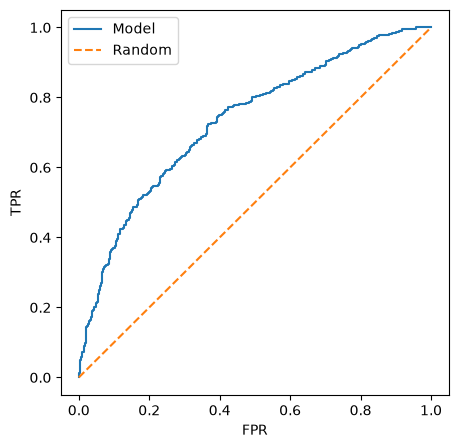

In [150]:
plt.figure(figsize=(5, 5))

plt.plot(fpr, tpr, label='Model')
plt.plot([0, 1], [0, 1], label='Random', linestyle='--')

plt.xlabel('FPR')
plt.ylabel('TPR')

plt.legend()

In [151]:
auc(fpr,tpr )

0.7318222288173319

In [167]:
conv=(y_pred>0.5).astype('int')

In [201]:
score=[]

thresolds= np.linspace(0, 1, 101)

for t in thresolds:

    predict_p = (y_pred>=t)
    predict_n = (y_pred<t)

    actual_p= (y_val==1)
    actual_n= (y_val==0)

    tp= (predict_p & actual_p).sum()
    tn= (predict_n & actual_n).sum()

    fp= (predict_p & actual_n).sum()
    fn= (predict_n & actual_p).sum()
    
    precision=tp /(tp +fp)
    recall= tp / (tp + fn)
    
    diff=abs(precision-recall)
    
    f1= ((precision * recall)/ (precision +recall))*2
    
    score.append((t,tp, tn , fp, fn , precision, recall, diff, f1))


C:\Users\princ\AppData\Local\Temp\ipykernel_29260\3633856491.py:19: RuntimeWarning: invalid value encountered in scalar divide
  precision=tp /(tp +fp)


In [202]:
col=['t','tp', 'tn' , 'fp', 'fn' , 'precision', 'recall', 'diff', 'f1']
df_scores= pd.DataFrame(score, columns=col)

In [203]:
df_scores

,t,tp,tn,fp,fn,precision,recall,diff,f1
0,0.00,586,0,414,0,0.586,1.000000,0.414000,0.738966
1,0.01,586,0,414,0,0.586,1.000000,0.414000,0.738966
2,0.02,586,0,414,0,0.586,1.000000,0.414000,0.738966
3,0.03,586,0,414,0,0.586,1.000000,0.414000,0.738966
4,0.04,586,0,414,0,0.586,1.000000,0.414000,0.738966
...,...,...,...,...,...,...,...,...,...
96,0.96,1,414,0,585,1.000,0.001706,0.998294,0.003407
97,0.97,0,414,0,586,NaN,0.000000,NaN,NaN
98,0.98,0,414,0,586,NaN,0.000000,NaN,NaN
99,0.99,0,414,0,586,NaN,0.000000,NaN,NaN


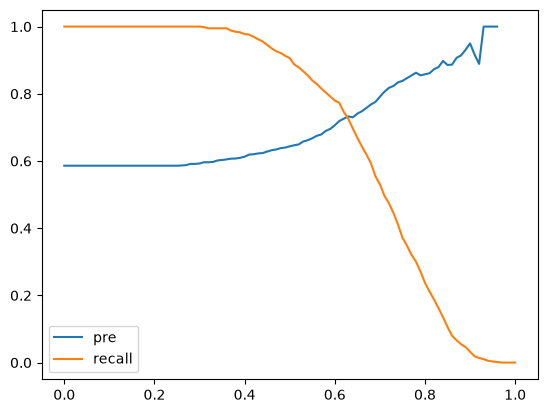

In [188]:
plt.plot(df_scores.t, df_scores['precision'], label='pre')
plt.plot(df_scores.t, df_scores['recall'], label='recall')
plt.legend()

In [200]:
df_scores[df_scores['diff']==df_scores['diff'].min()]

,t,tp,tn,fp,fn,precision,recall,diff
63,0.63,425,259,155,161,0.732759,0.725256,0.007503


In [205]:
df_scores[df_scores['f1']==df_scores['f1'].max()]

,t,tp,tn,fp,fn,precision,recall,diff,f1
41,0.41,572,62,352,14,0.619048,0.976109,0.357062,0.757616


Question 5:

In [224]:
def train(df,y_train, c=1.0):
    
    dicts=df[categorical_var + numerical_var].to_dict(orient="records")
    dv=DictVectorizer(sparse=False)
    
    X=dv.fit_transform(dicts)
    
    model= LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X,y_train)
    
    return dv, model    

In [225]:
def predict(df, dv, model):
    
    dicts=df[categorical_var + numerical_var].to_dict(orient="records")
    X=dv.transform(dicts)
    
    y_pred=model.predict_proba(X)[:,1]
    
    return y_pred    

In [226]:
from sklearn.model_selection import KFold

In [232]:
def cross_validation(df, number_of_splits, shuffle, random_state, c=1.0):
    
    kfold=KFold(
        n_splits=number_of_splits,
        shuffle=shuffle,
        random_state=random_state
    )
    auc_score=[]
    
    for train_idx, val_idx in kfold.split(df):
        
        df_train=df.iloc[train_idx]
        df_val=df.iloc[val_idx]
        
        y_train=df_train.converted.values
        y_val=df_val.converted.values
        
        dv, model=train(df_train,y_train,c)
        y_pred= predict(df_val, dv, model)
        
        score=roc_auc_score(y_val,y_pred)
        auc_score.append(score)
    
    return auc_score

In [233]:
score=cross_validation(df_full_train,number_of_splits=5, shuffle=True, random_state=1 )

In [234]:
score

[0.7305601027122453,
 0.7295726148196622,
 0.7363428071259397,
 0.7412454717957564,
 0.7209138590326581]

In [235]:
np.std(score)

np.float64(0.006853233151022138)

quest_6

In [245]:
mean_rco=[]
std_roc=[]
for c in [0.000001, 0.001, 1]:
    score=cross_validation(df_full_train,number_of_splits=5, shuffle=True, random_state=1 ,c=c)
    mean_rco.append(np.mean(score).round(3)), std_roc.append(np.std(score).round(3))
    

In [246]:
mean_rco, std_roc

([np.float64(0.732), np.float64(0.732), np.float64(0.732)],
 [np.float64(0.007), np.float64(0.007), np.float64(0.007)])